## Гипергеометрическое распределение



In [2]:
!pip3 install numpy scipy matplotlib

  Using cached scipy-1.18.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
Using cached scipy-1.18.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (35.3 MB)


In [30]:
import numpy as np
from scipy.stats import binom, norm, poisson
import matplotlib.pyplot as plt

In [2]:
def binom_exact_prob(k, n, p):
    return binom.pmf(k, n, p)

def binom_poisson_prob(k, n, p):
    return poisson.pmf(k, mu=n * p)

def binom_moivre_laplace(k, n, p):
    mu = n * p
    sigma = np.sqrt(n * p * (1 - p))
    return norm.pdf(k, loc=mu, scale=sigma)

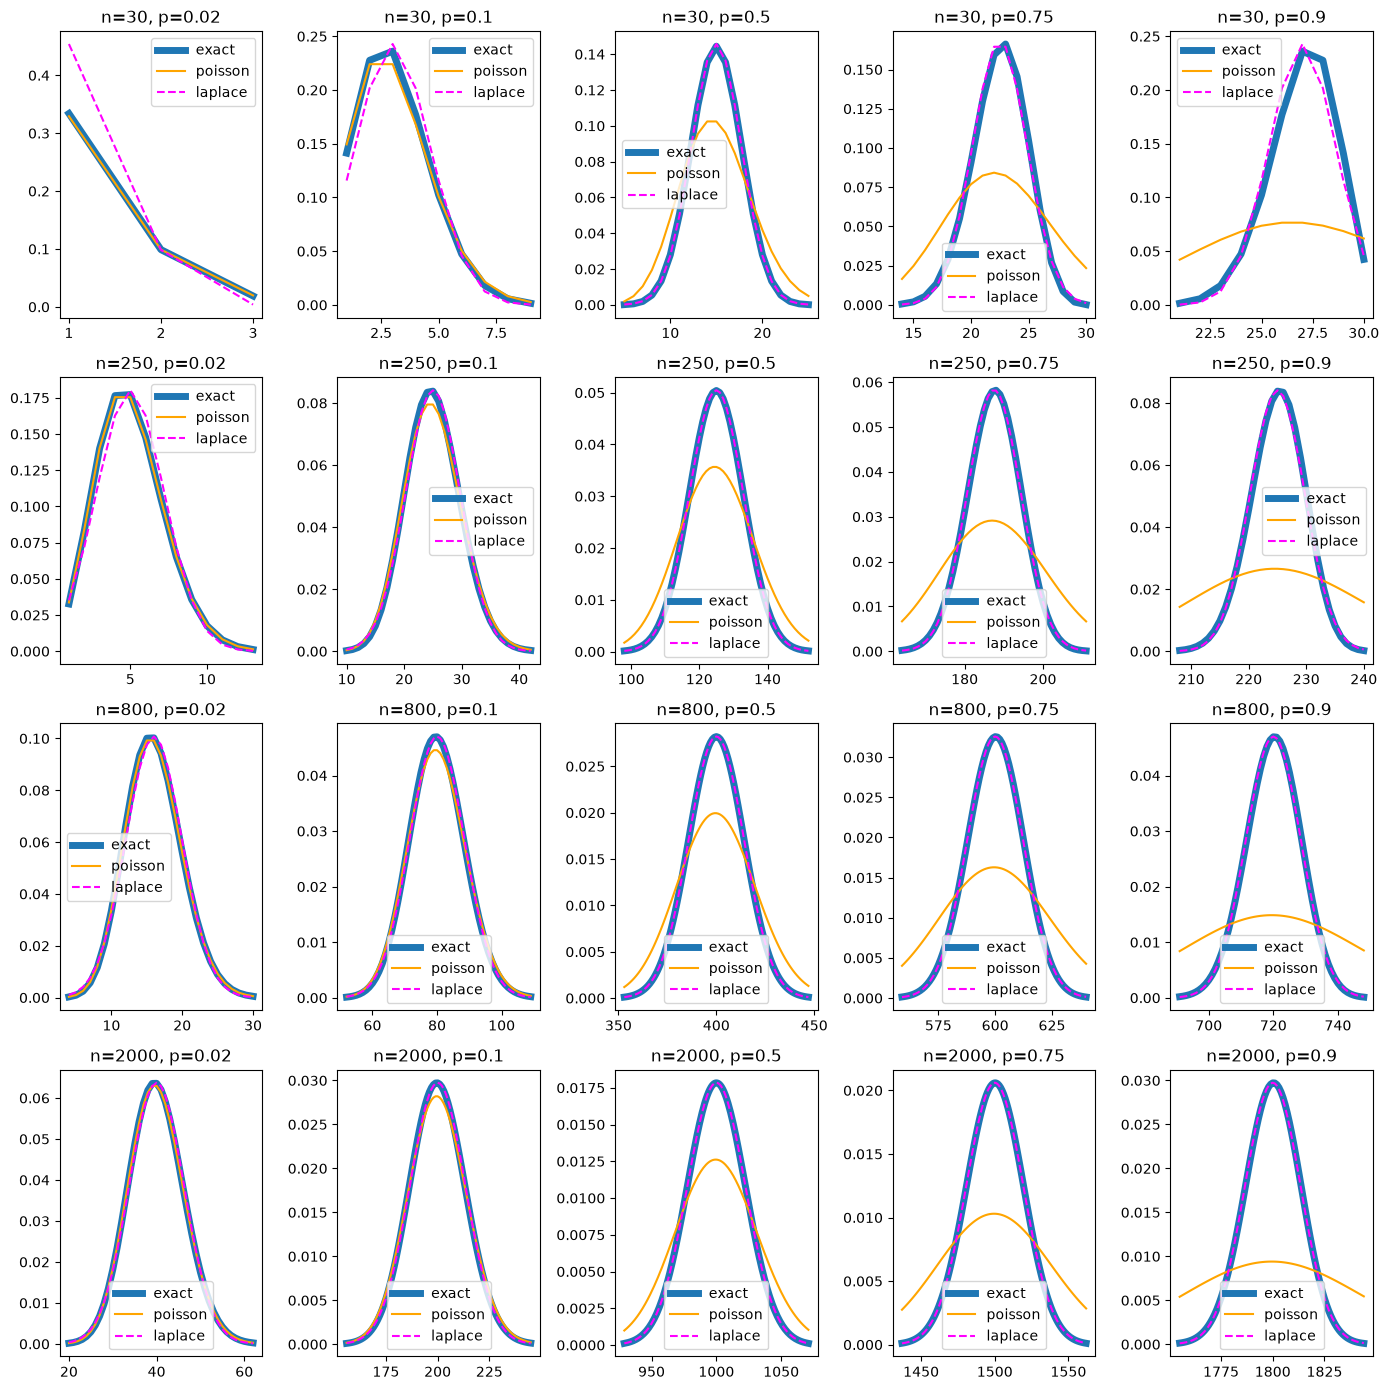

In [34]:
# Различные значения параметров, которые будем перебирать
# Будем считать со всеми k in [1:n]
ns = [30, 250, 800, 2000]
ps = [0.02, 0.1, 0.5, 0.75, 0.9]

# Помогает отрезать ненужную часть графика, где у всех распределений
# значение примерно 0. use_threshold=False отключает обрезание
threshold = 1e-4
use_threshold = True

fig, axes = plt.subplots(len(ns), len(ps), figsize=(14, 14))

for i, n in enumerate(ns):
    for j, p in enumerate(ps):
        ax = axes[i, j]
        ks = np.arange(1, n + 1)
        exact = binom_exact_prob(ks, n, p)
        poiss = binom_poisson_prob(ks, n, p)
        lapl = binom_moivre_laplace(ks, n, p)

        using_threshold = threshold if use_threshold else 0
        mask = (exact > using_threshold) & (poiss > using_threshold) & (lapl > using_threshold)

        ax.plot(ks[mask], exact[mask], label="exact", linewidth=5)
        ax.plot(ks[mask], poiss[mask], color='orange', label="poisson")
        ax.plot(ks[mask], lapl[mask], color='magenta', label="laplace", linestyle="--")

        ax.set_title(f"n={n}, p={p}")
        ax.legend()

plt.tight_layout()
plt.show()

По диаграмме видно следующее:
1) Приближение с помощью нормального распределения по локальной теореме Муавра-Лапласа очень точное
2) Распределение Пуассона лучше подходит в случае малого p

In [35]:
from scipy.stats import hypergeom

def hyperheom_exact(whole, whole_marked, take, expect_marked):
    return hypergeom.pmf(expect_marked, whole, whole_marked, take)

def hyperheom_binom(whole, whole_marked, take, expect_marked):
    return binom_exact_prob(expect_marked, take, whole_marked / whole)

def hyperheom_binom_poisson(whole, whole_marked, take, expect_marked):
    return binom_poisson_prob(expect_marked, take, whole_marked / whole)

def hyperheom_binom_moivre_laplace(whole, whole_marked, take, expect_marked):
    return binom_moivre_laplace(expect_marked, take, whole_marked / whole)

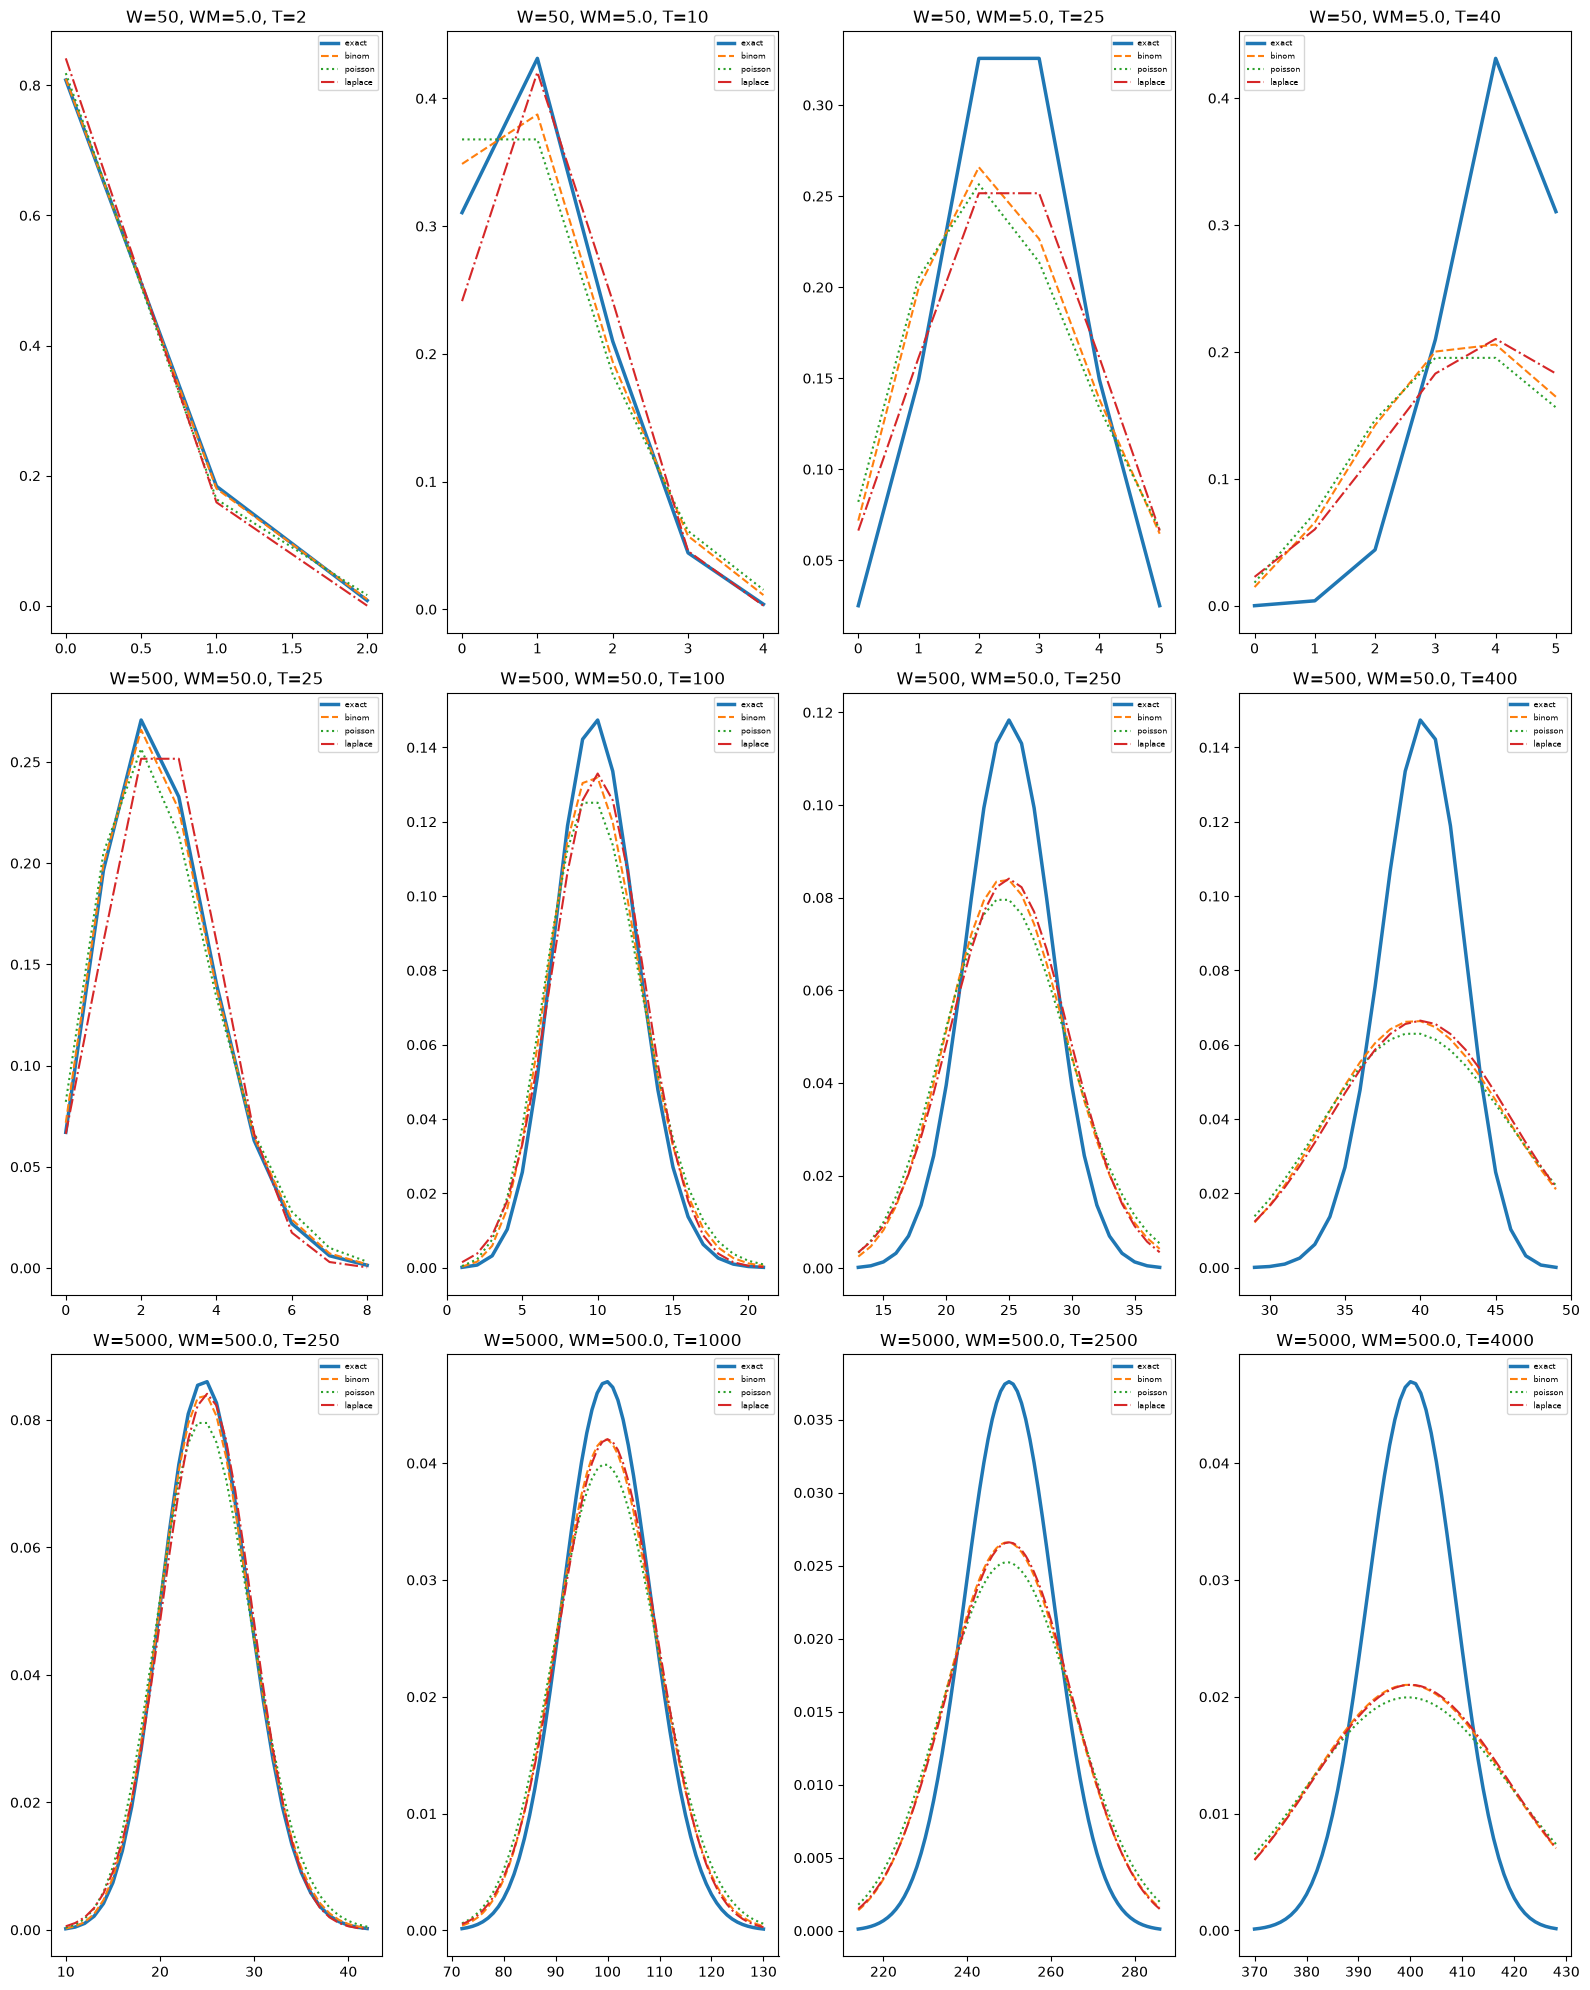

In [41]:

params = [
    (50, 50 * 0.1),
    (500, 500 * 0.1),
    (5000, 5000 * 0.1),
]
take_coefs = [0.05, 0.2, 0.5, 0.8]
threshold = 1e-4

fig, axes = plt.subplots(len(params), len(take_coefs), figsize=(16, 20))

for i, (whole, whole_marked) in enumerate(params):
    for j, take_coef in enumerate(take_coefs):

        take = int(take_coef * whole)

        ax = axes[i, j]
        ks = np.arange(0, take + 1)
        exact = hyperheom_exact(whole, whole_marked, take, ks)
        binom_approx = hyperheom_binom(whole, whole_marked, take, ks)
        poiss = hyperheom_binom_poisson(whole, whole_marked, take, ks)
        lapl = hyperheom_binom_moivre_laplace(whole, whole_marked, take, ks)

        mask = (exact > threshold) & (binom_approx > threshold) & (poiss > threshold) & (lapl > threshold)

        ax.plot(ks[mask], exact[mask], label="exact", linewidth=2.5)
        ax.plot(ks[mask], binom_approx[mask], label="binom", linestyle="--")
        ax.plot(ks[mask], poiss[mask], label="poisson", linestyle="dotted")
        ax.plot(ks[mask], lapl[mask], label="laplace", linestyle="dashdot")

        ax.set_title(f"W={whole}, WM={whole_marked}, T={take}")
        ax.legend(fontsize=6)

plt.tight_layout()
plt.show()

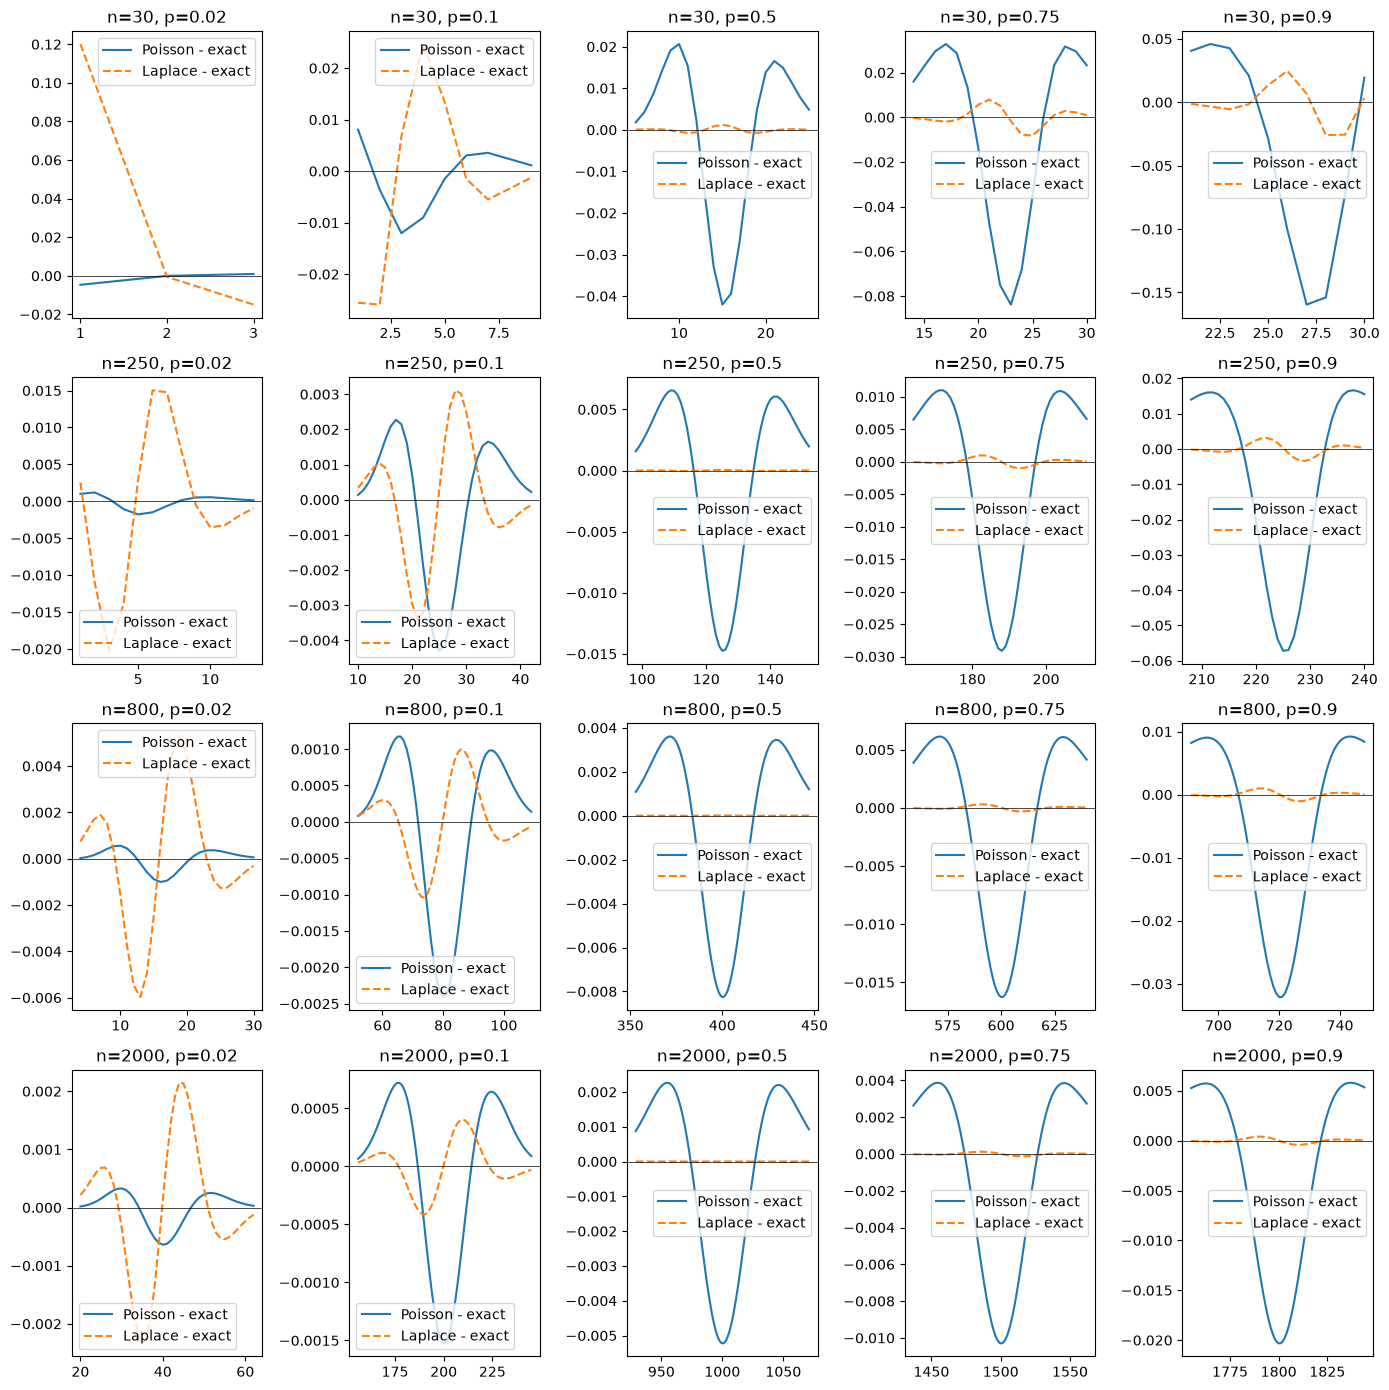

In [42]:
# Отклонения приближений от exact для биномиального
ns = [30, 250, 800, 2000]
ps = [0.02, 0.1, 0.5, 0.75, 0.9]
threshold = 1e-4

fig, axes = plt.subplots(len(ns), len(ps), figsize=(14, 14))

for i, n in enumerate(ns):
    for j, p in enumerate(ps):
        ax = axes[i, j]
        ks = np.arange(1, n + 1)
        exact = binom_exact_prob(ks, n, p)
        poiss = binom_poisson_prob(ks, n, p)
        lapl = binom_moivre_laplace(ks, n, p)

        mask = (exact > threshold) & (poiss > threshold) & (lapl > threshold)

        ax.plot(ks[mask], poiss[mask] - exact[mask], label="Poisson - exact", linewidth=1.5)
        ax.plot(ks[mask], lapl[mask] - exact[mask], label="Laplace - exact", linestyle="--")

        ax.axhline(0, color="black", linewidth=0.5)
        ax.set_title(f"n={n}, p={p}")
        ax.legend()

plt.tight_layout()
plt.show()

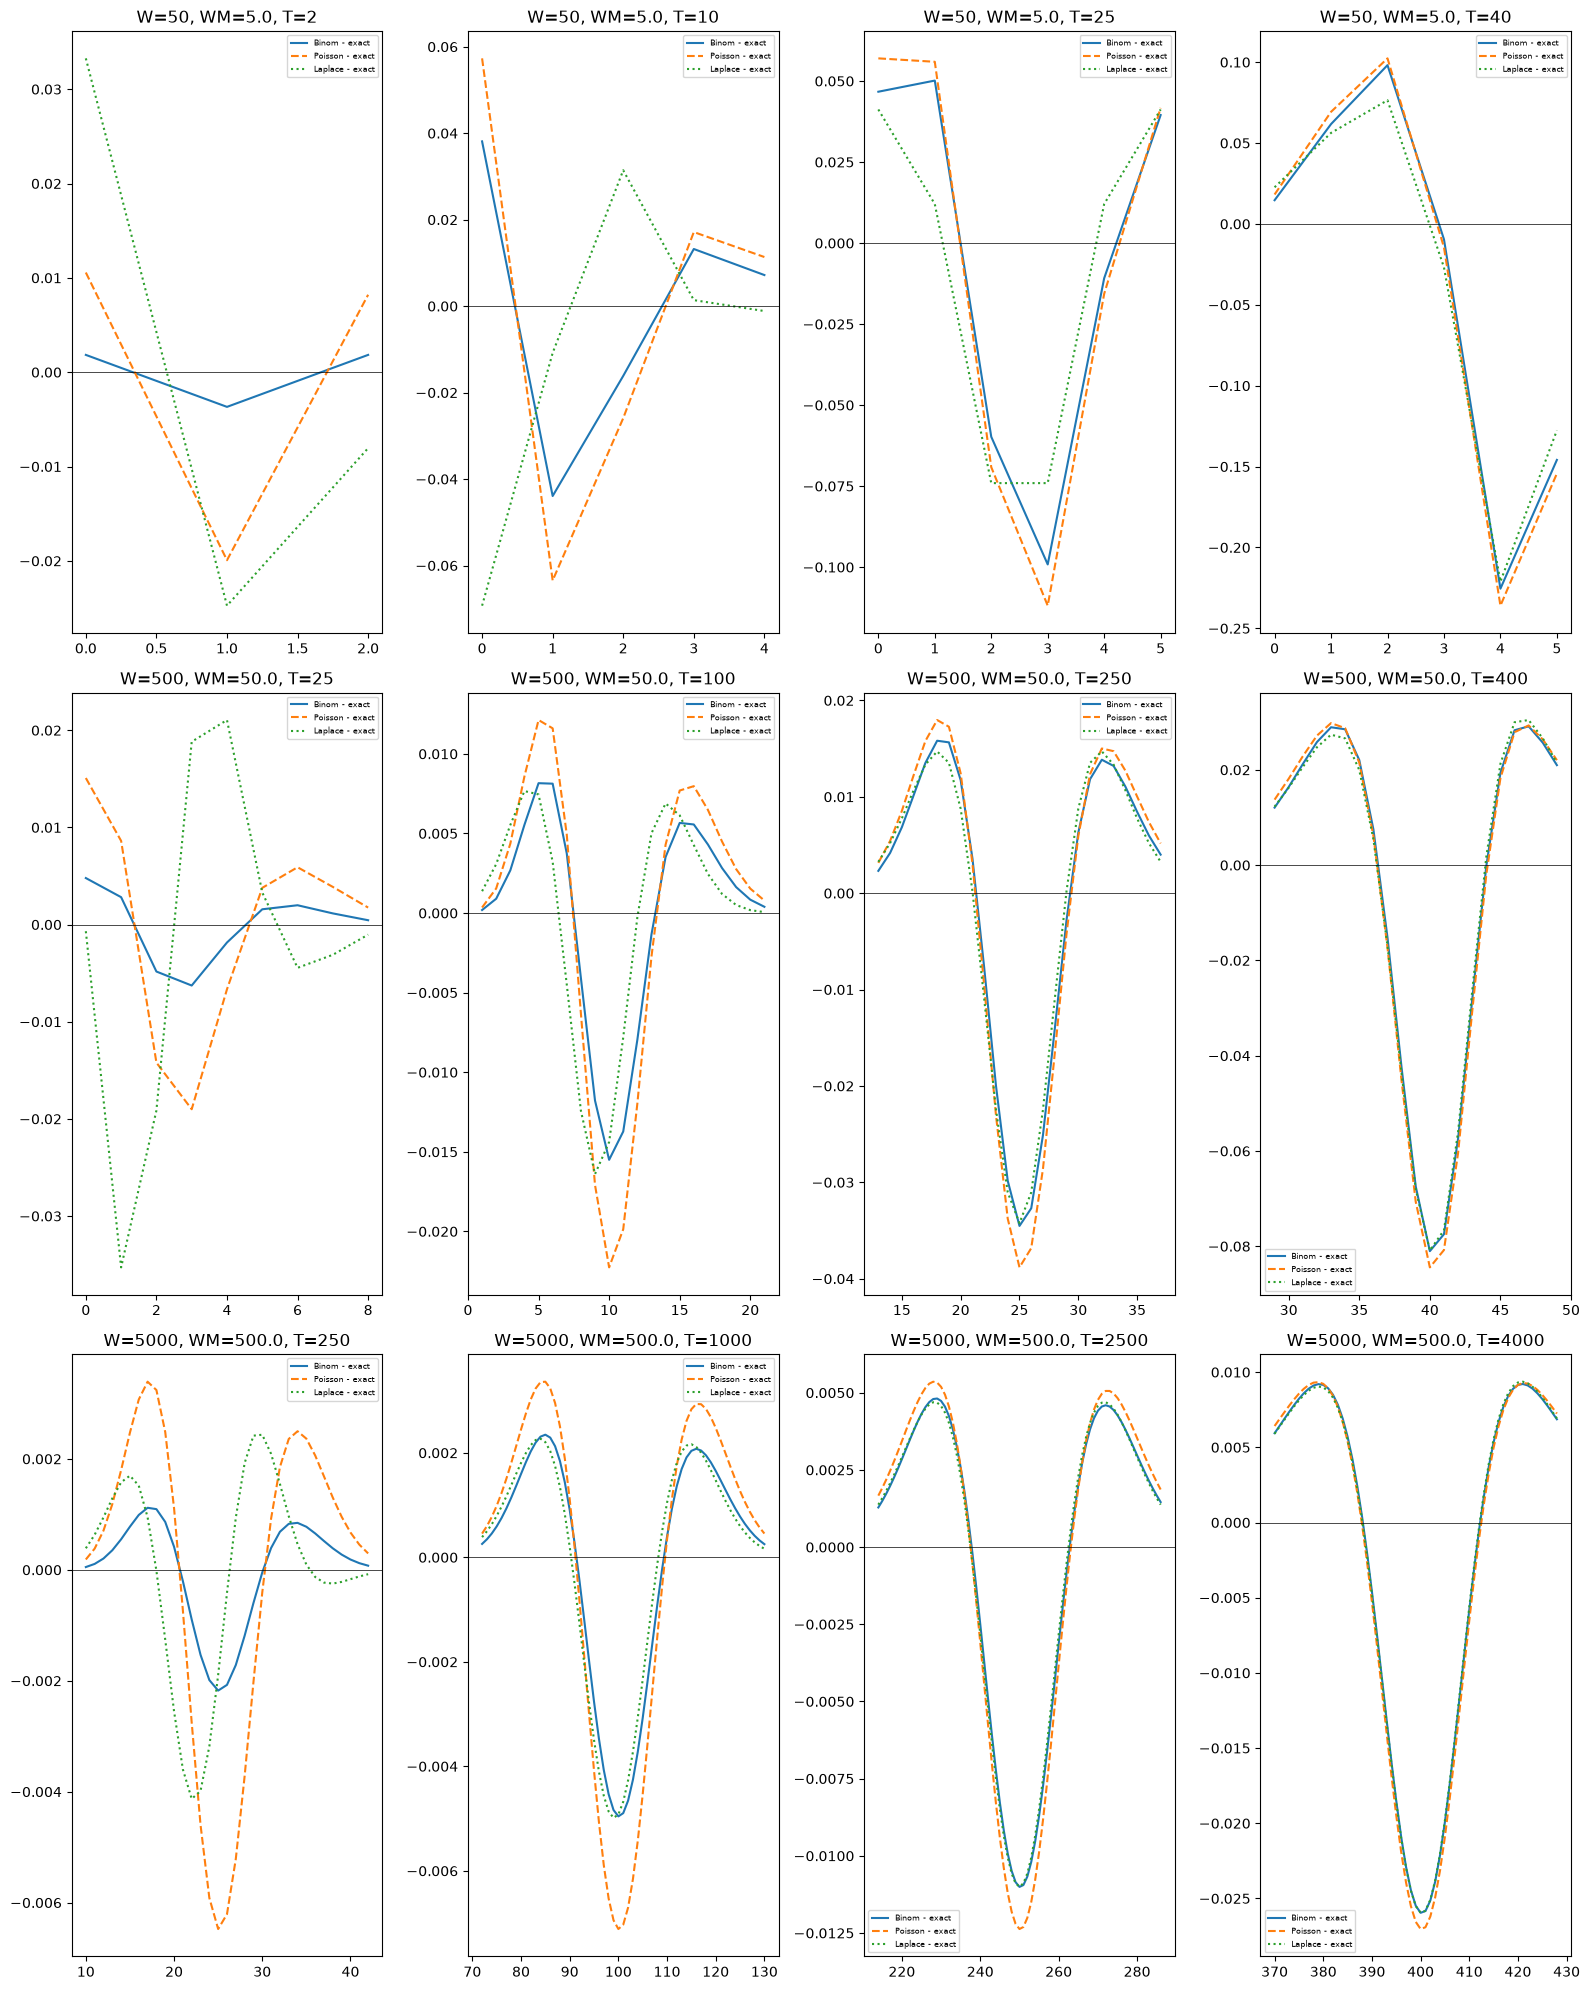

In [43]:
# Отклонения приближений от exact для гипергеометрического
params = [
    (50, 50 * 0.1),
    (500, 500 * 0.1),
    (5000, 5000 * 0.1),
]
take_coefs = [0.05, 0.2, 0.5, 0.8]
threshold = 1e-4

fig, axes = plt.subplots(len(params), len(take_coefs), figsize=(16, 20))

for i, (whole, whole_marked) in enumerate(params):
    for j, take_coef in enumerate(take_coefs):

        take = int(take_coef * whole)
        ax = axes[i, j]
        ks = np.arange(0, take + 1)
        exact = hyperheom_exact(whole, whole_marked, take, ks)
        binom_approx = hyperheom_binom(whole, whole_marked, take, ks)
        poiss = hyperheom_binom_poisson(whole, whole_marked, take, ks)
        lapl = hyperheom_binom_moivre_laplace(whole, whole_marked, take, ks)

        mask = (exact > threshold) & (binom_approx > threshold) & (poiss > threshold) & (lapl > threshold)

        ax.plot(ks[mask], binom_approx[mask] - exact[mask], label="Binom - exact", linewidth=1.5)
        ax.plot(ks[mask], poiss[mask] - exact[mask], label="Poisson - exact", linestyle="--")
        ax.plot(ks[mask], lapl[mask] - exact[mask], label="Laplace - exact", linestyle="dotted")

        ax.axhline(0, color="black", linewidth=0.5)
        ax.set_title(f"W={whole}, WM={whole_marked}, T={take}")
        ax.legend(fontsize=6)

plt.tight_layout()
plt.show()